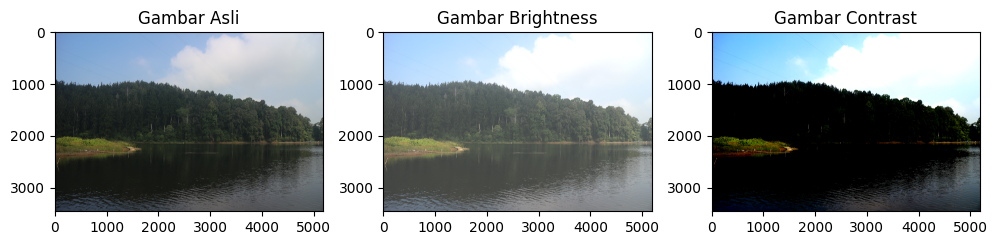

In [3]:
import imageio.v3 as image
import numpy as np
import matplotlib.pyplot as plt

img = "jawa2.jpg"
my_image = image.imread(img)

def brightness(img,factor):
    img_result = img.astype(np.float32)
    img_result = img_result +factor
    img_result = np.clip(img_result,0,255)
    return img_result.astype(np.uint8)

def contrast(img,factor):
    mean = 128
    img_result = img.astype(np.float32)
    img_result = mean + factor * (img_result - mean)
    img_result = np.clip(img_result,0,255)
    return img_result.astype(np.uint8)

bright = brightness(my_image,50)
contrast = contrast(my_image,2)

plt.figure(figsize=(10,10))

plt.subplot(1,3,1)
plt.imshow(my_image,origin="upper")
plt.title("Gambar Asli")

plt.subplot(1,3,2)
plt.imshow(bright,origin="upper")
plt.title("Gambar Brightness")

plt.subplot(1,3,3)
plt.imshow(contrast,origin="upper")

plt.title("Gambar Contrast")
plt.tight_layout()
plt.show()

/tmp/ipykernel_2651/3031160400.py:14: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread("jawa2.jpg")


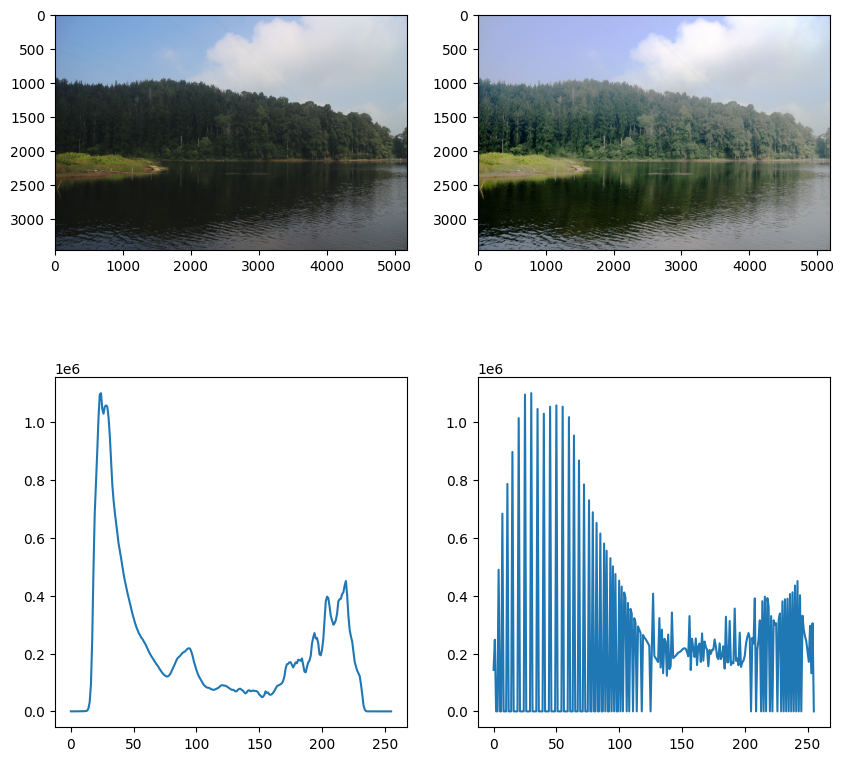

In [11]:
import imageio as img
import numpy as np
import matplotlib.pyplot as plt

def hist_equal(image):
    hist, bins = np.histogram(image.flatten(), bins=256, range=[0,256])
    cdf = hist.cumsum()
    cdf_normal = (cdf/cdf.max()) * 255

    image_equalized = np. interp(image.flatten(), bins[:-1], cdf_normal)

    return image_equalized.reshape(image.shape).astype(np.uint8)

image = img.imread("jawa2.jpg")

result = hist_equal(image)

hist_img, bins = np.histogram(image.flatten(), bins=256, range=[0,256])
hist_result, bins = np.histogram(result.flatten(), bins=256, range=[0,256])

plt.figure(figsize=(10,10))

plt.subplot(2,2,1)
plt.imshow(image)

plt.subplot(2,2,2)
plt.imshow(result)

plt.subplot(2,2,3)
plt.plot(hist_img)

plt.subplot(2,2,4)
plt.plot(hist_result)

plt.show()